# Anisotropic materials and birefringence in FDTDX

This notebook shows how to define anisotropic materials in [FDTDX](https://fdtdx.readthedocs.io/en/latest/) and then uses one of them to simulate birefringence. A birefringent material has a refractive index that depends on the polarization of the light passing through it. As an example we build a quarter-wave plate, a slab that turns linearly polarized light into circularly polarized light.

## 1. Setup

In [3]:
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

import fdtdx

%matplotlib inline

## 2. Anisotropic materials in FDTDX

Every material property in FDTDX (`permittivity`, `permeability`, `electric_conductivity`, `magnetic_conductivity`) is stored as a 3x3 tensor, written as a 9-tuple `(xx, xy, xz, yx, yy, yz, zx, zy, zz)`. See the [`fdtdx.Material`](https://fdtdx.readthedocs.io/en/latest/api/fdtdx.Material.html) documentation for details. The tensor can be given in three ways:

| Input | Meaning | Example |
|---|---|---|
| scalar `float` | isotropic: the same value on all three diagonal entries, no off-diagonal terms | `permittivity=2.25` |
| 3-tuple `(εx, εy, εz)` | diagonally anisotropic, e.g. a uniaxial or biaxial crystal whose axes are aligned with the grid | `permittivity=(2.75, 2.75, 2.21)` |
| 9-tuple or nested 3x3 | fully anisotropic, including off-diagonal terms, e.g. a crystal whose optic axis is tilted relative to the grid | `permittivity=((2.48, 0, 0.27), (0, 2.75, 0), (0.27, 0, 2.48))` |

`Material` also has attributes such as `is_isotropic_permittivity`, `is_diagonally_anisotropic_permittivity` and `is_all_diagonally_anisotropic`. We use them below to check what was built.

In [6]:
# (a) Isotropic material, e.g. plain glass
glass = fdtdx.Material(permittivity=2.25)  # n = 1.5
print("Isotropic glass:")
print("  permittivity tensor:", glass.permittivity)
print("  is_isotropic_permittivity:", glass.is_isotropic_permittivity)

# (b) Diagonally anisotropic material: a uniaxial crystal with its optic axis
# along the z grid axis, so eps_x = eps_y = eps_o (ordinary) and eps_z = eps_e (extraordinary)
uniaxial = fdtdx.Material(permittivity=(2.749, 2.749, 2.208))
print("\nUniaxial crystal (optic axis along grid z):")
print("  permittivity tensor:", uniaxial.permittivity)
print("  is_diagonally_anisotropic_permittivity:", uniaxial.is_diagonally_anisotropic_permittivity)
print("  is_isotropic_permittivity:", uniaxial.is_isotropic_permittivity)

# (c) Fully anisotropic material: the same crystal, but with its optic axis tilted
# by 30 degrees within the x-z plane. This adds off-diagonal (xz and zx) components.
def tilted_uniaxial_permittivity(eps_o, eps_e, theta_rad):
    """Permittivity tensor of a uniaxial crystal whose optic axis is rotated by
    `theta_rad` about the y-axis (i.e. tilted within the x-z plane)."""
    c, s = np.cos(theta_rad), np.sin(theta_rad)
    exx = float(eps_o * c**2 + eps_e * s**2)
    ezz = float(eps_o * s**2 + eps_e * c**2)
    exz = float((eps_e - eps_o) * s * c)
    return (
        (exx, 0.0, exz),
        (0.0, eps_o, 0.0),
        (exz, 0.0, ezz),
    )

tilted = fdtdx.Material(permittivity=tilted_uniaxial_permittivity(2.749, 2.208, np.deg2rad(30)))
print("\nTilted uniaxial crystal (optic axis at 30 deg to grid z):")
print("  permittivity tensor:", tilted.permittivity)
print("  is_all_diagonally_anisotropic:", tilted.is_all_diagonally_anisotropic)
print("  is_isotropic_permittivity:", tilted.is_isotropic_permittivity)

Isotropic glass:
  permittivity tensor: (2.25, 0.0, 0.0, 0.0, 2.25, 0.0, 0.0, 0.0, 2.25)
  is_isotropic_permittivity: True

Uniaxial crystal (optic axis along grid z):
  permittivity tensor: (2.749, 0.0, 0.0, 0.0, 2.749, 0.0, 0.0, 0.0, 2.208)
  is_diagonally_anisotropic_permittivity: True
  is_isotropic_permittivity: False

Tilted uniaxial crystal (optic axis at 30 deg to grid z):
  permittivity tensor: (2.6137500000000005, 0.0, -0.2342598717236906, 0.0, 2.749, 0.0, -0.2342598717236906, 0.0, 2.3432500000000003)
  is_all_diagonally_anisotropic: False
  is_isotropic_permittivity: False


## 3. Birefringence

In a birefringent crystal the response to an electric field depends on the direction of the field relative to a crystal axis called the optic axis. A uniaxial crystal has two principal refractive indices:

* the ordinary index $n_o$ for light polarized perpendicular to the optic axis,
* the extraordinary index $n_e$ for light polarized parallel to the optic axis.

Because $n_o \neq n_e$, the two polarization components travel with different phase velocities. This has two consequences.

1. **Phase retardation.** If the light travels perpendicular to the optic axis, both components keep the same direction but acquire a phase difference
$$\Delta\varphi = \frac{2\pi\,(n_o - n_e)\,d}{\lambda},$$
where $d$ is the thickness of the slab and $\lambda$ the vacuum wavelength. Waveplates work this way, and this is the effect we simulate.
2. **Walk-off.** If the optic axis is tilted with respect to the propagation direction, the ordinary and extraordinary rays separate inside the crystal. This is the double refraction known from calcite. We do not simulate it here.

For a quarter-wave plate we want $\Delta\varphi = 90^\circ$, which gives $d = \lambda / \big(4\,|n_o - n_e|\big)$. If linearly polarized light at 45° to the optic axis enters such a plate, the two components have equal amplitude and end up a quarter period apart, so the output is circularly polarized.

We use $n_o = 1.658$ and $n_e = 1.486$, the values of calcite at 589 nm. Materials in FDTDX are non-dispersive, so these constants apply at every wavelength. The design wavelength of 1550 nm is only a convenient choice for the simulation.

In [9]:
n_o = 1.658   # ordinary index
n_e = 1.486   # extraordinary index (n_e < n_o: negative uniaxial crystal, like calcite)
eps_o = n_o**2
eps_e = n_e**2
delta_n = n_o - n_e

c0 = 299792458.0          # speed of light (m/s)
wavelength = 1.55e-6      # design wavelength (m)
f0 = c0 / wavelength      # corresponding frequency (Hz)
grid_spacing = 25e-9      # FDTD cell size (m), roughly 40 cells per wavelength inside the slab

# quarter-wave condition: (n_o - n_e) * d = lambda / 4
slab_thickness = wavelength / (4 * delta_n)
print(f"eps_o = {eps_o:.4f}, eps_e = {eps_e:.4f}, delta_n = {delta_n:.4f}")
print(f"Quarter-wave slab thickness: {slab_thickness*1e6:.3f} um")

eps_o = 2.7490, eps_e = 2.2082, delta_n = 0.1720
Quarter-wave slab thickness: 2.253 um


## 4. Simulation setup

A waveplate is normally analyzed with a plane wave at normal incidence on a slab that extends infinitely in the transverse directions. Then there is a single propagation direction, and the result depends only on the slab thickness and the two indices.

* **Plane wave source.** `UniformPlaneSource` launches a plane wave along $+z$. A beam-like source (`GaussianPlaneSource`) or a point source would add diffraction and a range of propagation directions, so the retardation would no longer be one well-defined number. The polarization vector points 45° between $x$ and $y$, so $E_x$ and $E_y$ start with equal amplitude and phase.
* **Periodic boundaries in $x$ and $y$.** They make the slab and the wave infinite in the transverse plane. Nothing varies in $x$ and $y$, so only 4 cells are needed in those directions and the simulation is effectively one-dimensional.
* **PML in $z$.** It absorbs the transmitted and the reflected wave.
* **Gaussian pulse.** `GaussianPulseProfile` gives a pulse with a Gaussian spectrum. One run then covers a whole band of frequencies, so we can read off the retardation at many wavelengths at once. `spectral_width` is the standard deviation of the amplitude spectrum. A continuous-wave source would only excite a single frequency.
* **Reference run.** We simulate the scene twice, once with the slab and once without. The run without the slab records the incident pulse at the same position. Dividing the transmitted spectrum by the incident one removes the spectrum of the source and leaves only the response of the slab.
* **Detectors.** A `FieldDetector` at a single point behind the slab records $E_x$ and $E_y$ at every time step. A second one along the whole $z$ axis records the pulse while it crosses the slab.

The optic axis of the slab points along $x$. So $E_x$ sees $\varepsilon_e$ while $E_y$ and $E_z$ see $\varepsilon_o$, which is the diagonal material from section 2(b) with the axes permuted.

In [12]:
def build_scene(with_slab, seed=0):
    """Build the simulation scene, with or without the birefringent slab."""
    key = jax.random.PRNGKey(seed)
    object_list, constraints = [], []

    config = fdtdx.SimulationConfig(
        time=150e-15,                           # long enough for the pulse and its reflections to pass
        grid=fdtdx.UniformGrid(spacing=grid_spacing),
        dtype=jnp.float32,
        courant_factor=0.99,
    )

    # Vacuum volume: only 4 cells wide in x and y (periodic), 7 um long in z
    volume = fdtdx.SimulationVolume(
        partial_real_shape=(4 * grid_spacing, 4 * grid_spacing, 7e-6),
        material=fdtdx.Material(permittivity=1.0, permeability=1.0),
    )
    object_list.append(volume)

    # PML in z, periodic in x and y
    bound_cfg = fdtdx.BoundaryConfig.from_uniform_bound(
        thickness=20,
        boundary_type="pml",
        override_types={"min_x": "periodic", "max_x": "periodic",
                        "min_y": "periodic", "max_y": "periodic"},
    )
    bound_dict, c_list = fdtdx.boundary_objects_from_config(bound_cfg, volume)
    object_list.extend(bound_dict.values())
    constraints.extend(c_list)

    # Plane wave travelling along +z, linearly polarized at 45 degrees to x
    source = fdtdx.UniformPlaneSource(
        partial_grid_shape=(None, None, 1),
        fixed_E_polarization_vector=(1 / np.sqrt(2), 1 / np.sqrt(2), 0.0),
        wave_character=fdtdx.WaveCharacter(wavelength=wavelength),
        temporal_profile=fdtdx.GaussianPulseProfile(
            spectral_width=fdtdx.WaveCharacter(frequency=25e12),   # std of the amplitude spectrum
            center_wave=fdtdx.WaveCharacter(wavelength=wavelength),
        ),
        direction="+",
        name="Source",
    )
    object_list.append(source)
    constraints.append(
        source.place_relative_to(
            volume,
            axes=(0, 1, 2),
            own_positions=(0, 0, -1),
            other_positions=(0, 0, -1),
            margins=(0, 0, 1.0e-6),  # 1 um inside the -z end of the volume
        )
    )

    # Birefringent slab in the middle of the volume. Optic axis along x:
    # Ex sees eps_e, Ey and Ez see eps_o.
    if with_slab:
        slab = fdtdx.UniformMaterialObject(
            partial_real_shape=(None, None, slab_thickness),
            material=fdtdx.Material(permittivity=(eps_e, eps_o, eps_o)),
            name="Slab",
            color=fdtdx.colors.LIGHT_BLUE,
        )
        object_list.append(slab)
        constraints.append(slab.place_at_center(volume))
        constraints.extend(slab.same_position_and_size(volume, axes=(0, 1)))

    # Point detector 0.5 um behind the position of the slab's rear face
    point_detector = fdtdx.FieldDetector(
        name="Behind",
        partial_grid_shape=(1, 1, 1),
        components=("Ex", "Ey"),
        switch=fdtdx.OnOffSwitch(interval=1),   # record every time step
    )
    object_list.append(point_detector)
    constraints.append(point_detector.place_at_center(volume, axes=(0, 1)))
    constraints.append(
        point_detector.place_relative_to(
            volume, axes=2, own_positions=0, other_positions=0,
            margins=slab_thickness / 2 + 0.5e-6,
        )
    )

    # Detector along the whole z axis, to see the pulse inside and outside the slab
    line_detector = fdtdx.FieldDetector(
        name="Line",
        partial_grid_shape=(1, 1, None),
        components=("Ex", "Ey"),
        switch=fdtdx.OnOffSwitch(interval=2),
    )
    object_list.append(line_detector)
    constraints.append(line_detector.place_at_center(volume, axes=(0, 1)))
    constraints.extend(line_detector.same_position_and_size(volume, axes=2))

    objects, arrays, params, config, _ = fdtdx.place_objects(
        object_list=object_list, config=config, constraints=constraints, key=key,
    )
    return objects, arrays, params, config, key


def run_scene(objects, arrays, params, config, key):
    def sim_fn(params, arrays, key):
        arrays, new_objects, _ = fdtdx.apply_params(arrays, objects, params, key)
        _, arrays = fdtdx.run_fdtd(arrays=arrays, objects=new_objects, config=config, key=key,
                                   show_progress=False)
        return arrays
    return jax.jit(sim_fn)(params, arrays, key)

## 5. Running the simulations

First the scene with the slab, then the same scene without it as reference. Both runs take only a few seconds because the problem is effectively one-dimensional.

In [15]:
# with slab
objects, arrays, params, config, key = build_scene(with_slab=True)
arrays_slab = run_scene(objects, arrays, params, config, key)

# reference without slab (same source, same detector positions)
objects_ref, arrays_r, params_r, config_ref, key_r = build_scene(with_slab=False)
arrays_ref = run_scene(objects_ref, arrays_r, params_r, config_ref, key_r)

print("Both simulations finished.")

Both simulations finished.


## 6. Geometry and pulse propagation

Before looking at the polarization we check the geometry. The $x$ and $y$ extent of the volume is only 4 cells because of the periodic boundaries, so a side view would show just a thin strip. Instead we plot the diagonal permittivity components along $z$ as FDTDX stored them, together with the positions of the PML, the source and the point detector. $\varepsilon_{xx}$ is what $E_x$ experiences and $\varepsilon_{yy}$ is what $E_y$ experiences. The two differ inside the slab and are equal to 1 in vacuum.

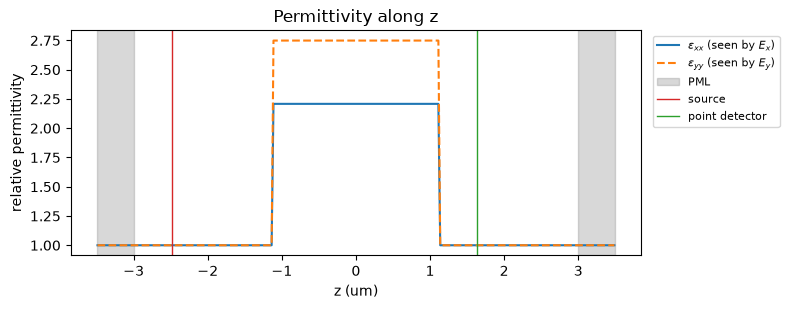

In [18]:
res = grid_spacing
inv_eps = np.asarray(arrays.inv_permittivities)          # shape (3, Nx, Ny, Nz) for a diagonal material
nz = inv_eps.shape[-1]
z_um = ((np.arange(nz) + 0.5) * res - nz * res / 2) * 1e6  # cell centers, z = 0 is the middle of the volume

def z_of(name):
    return z_um[objects[name].grid_slice[2].start]       # z position of the first cell of an object

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(z_um, 1 / inv_eps[0, 1, 1, :], label=r"$\varepsilon_{xx}$ (seen by $E_x$)")
ax.plot(z_um, 1 / inv_eps[1, 1, 1, :], "--", label=r"$\varepsilon_{yy}$ (seen by $E_y$)")
pml_um = 20 * res * 1e6
ax.axvspan(z_um[0] - res * 5e5, z_um[0] - res * 5e5 + pml_um, color="gray", alpha=0.3, label="PML")
ax.axvspan(z_um[-1] + res * 5e5 - pml_um, z_um[-1] + res * 5e5, color="gray", alpha=0.3)
ax.axvline(z_of("Source"), color="tab:red", lw=1, label="source")
ax.axvline(z_of("Behind"), color="tab:green", lw=1, label="point detector")
ax.set_xlabel("z (um)")
ax.set_ylabel("relative permittivity")
ax.set_title("Permittivity along z")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

Now we look at the line detector, which recorded $E_x$ and $E_y$ along the whole $z$ axis over time. Each panel below is a space-time diagram: position on the horizontal axis, time on the vertical axis, and the color shows the field. The pulse appears as a diagonal band. The slope of the band is the inverse of the propagation speed, so a steeper slope means slower propagation.

Outside the slab the pulse travels at the speed of light. Between the dashed lines it is slower, so the band is steeper there. Weak reflected pulses run backwards (towards negative $z$) from the two slab faces. The delay between $E_x$ and $E_y$ is only about a femtosecond, too small to see in this view. It is resolved in the next section.

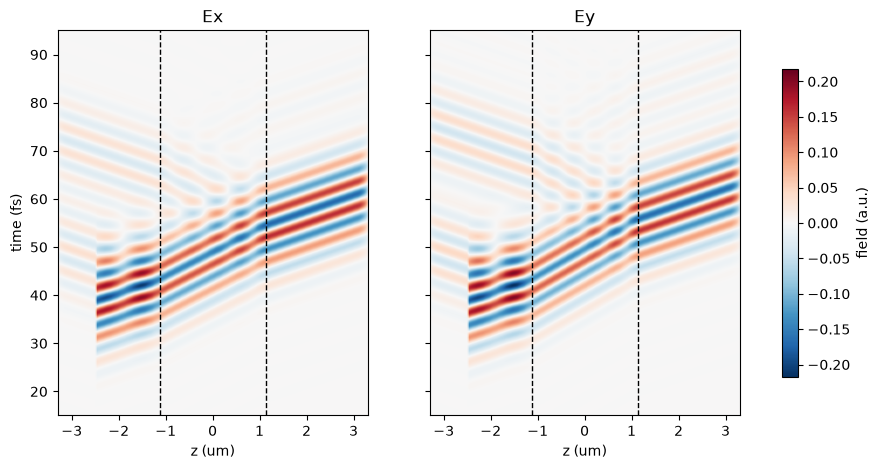

In [21]:
line = np.asarray(arrays_slab.detector_states["Line"]["fields"])   # (time, component, 1, 1, z)
line = line.reshape(line.shape[0], line.shape[1], -1)
dt = config.time_step_duration
t_line_fs = np.arange(line.shape[0]) * 2 * dt * 1e15              # detector records every 2nd step

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
vmax = np.abs(line).max()
for i, (ax, name) in enumerate(zip(axes, ["Ex", "Ey"])):
    im = ax.imshow(
        line[:, i, :], origin="lower", aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax,
        extent=[z_um[0], z_um[-1], t_line_fs[0], t_line_fs[-1]],
    )
    for z_edge in (-slab_thickness / 2 * 1e6, slab_thickness / 2 * 1e6):
        ax.axvline(z_edge, color="k", ls="--", lw=1)
    ax.set_title(name)
    ax.set_xlabel("z (um)")
    ax.set_xlim(-3.3, 3.3)
    ax.set_ylim(15, 95)
axes[0].set_ylabel("time (fs)")
fig.colorbar(im, ax=axes, label="field (a.u.)", shrink=0.8)
plt.show()

## 7. Polarization state behind the slab

We now compare the field at the point detector in the two runs. In the run without the slab the detector sees the incident pulse, and in the run with the slab it sees the pulse after the slab. The slab also reflects a small part of the light backwards, which is why the transmitted amplitude is slightly lower.

Field in the last 5 fs relative to the peak: 2.8e-05


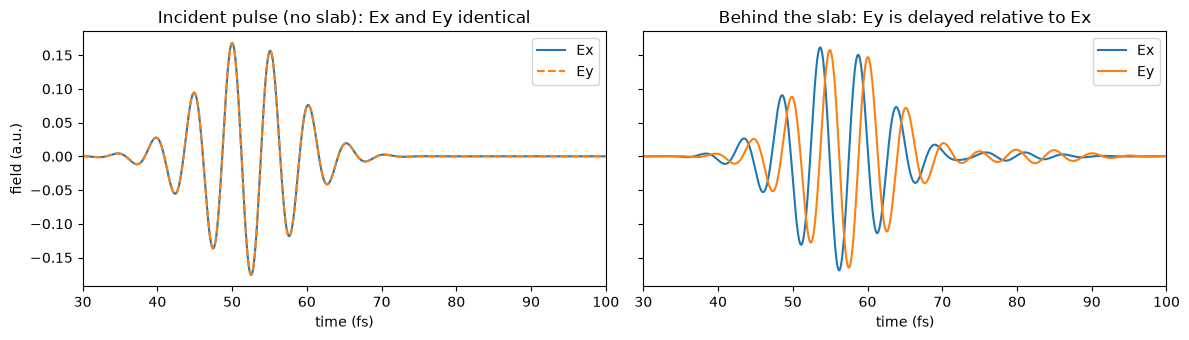

In [24]:
CANONICAL_ORDER = ("Ex", "Ey", "Ez", "Hx", "Hy", "Hz")

def get_trace(objs, arrs, detector_name, component):
    det = objs[detector_name]
    comp_order = [c for c in CANONICAL_ORDER if c in det.components]
    idx = comp_order.index(component)
    raw = np.asarray(arrs.detector_states[detector_name]["fields"])
    return raw[:, idx].reshape(-1)  # drop the size-1 spatial axes, keep time

ex_in, ey_in = get_trace(objects_ref, arrays_ref, "Behind", "Ex"), get_trace(objects_ref, arrays_ref, "Behind", "Ey")
ex_out, ey_out = get_trace(objects, arrays_slab, "Behind", "Ex"), get_trace(objects, arrays_slab, "Behind", "Ey")

# the detector records every simulation step
t_fs = np.arange(len(ex_in)) * config.time_step_duration * 1e15

# The simulation must be long enough for the fields to have died out at the end of the trace
tail = slice(-int(5e-15 / config.time_step_duration), None)
print(f"Field in the last 5 fs relative to the peak: "
      f"{max(np.abs(ex_out[tail]).max(), np.abs(ey_out[tail]).max()) / max(np.abs(ex_out).max(), np.abs(ey_out).max()):.1e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
axes[0].plot(t_fs, ex_in, label="Ex")
axes[0].plot(t_fs, ey_in, "--", label="Ey")
axes[0].set_title("Incident pulse (no slab): Ex and Ey identical")
axes[1].plot(t_fs, ex_out, label="Ex")
axes[1].plot(t_fs, ey_out, label="Ey")
axes[1].set_title("Behind the slab: Ey is delayed relative to Ex")
for ax in axes:
    ax.set_xlabel("time (fs)")
    ax.set_xlim(30, 100)
    ax.legend()
axes[0].set_ylabel("field (a.u.)")
plt.tight_layout()
plt.show()

### Reading the $E_x$-$E_y$ plot

At the detector position the electric field vector lies in the $x$-$y$ plane. If we plot $E_y$ against $E_x$ with time as the curve parameter, the curve shows how the tip of the field vector moves. Its shape depends only on the phase difference $\Delta\varphi$ between the two components and on their relative amplitude. For a monochromatic wave with $E_x = A\cos(\omega t)$ and $E_y = A\cos(\omega t - \Delta\varphi)$:

* $\Delta\varphi = 0$ or $180^\circ$: the two components peak at the same time (or exactly opposite). The curve is a straight line at +45° (or −45°). This is linear polarization.
* $\Delta\varphi = 90^\circ$: when $E_x$ is at its maximum $E_y$ is zero and vice versa. With equal amplitudes the curve is a circle. This is circular polarization.
* any other value: an ellipse with a tilted axis. This is elliptical polarization.

The sign of $\Delta\varphi$ sets the sense of rotation. With $E_y$ lagging $E_x$ the tip turns counterclockwise in the $E_x$-$E_y$ plane, and with $E_y$ leading it turns clockwise.

The figure below shows these cases for ideal monochromatic waves of equal amplitude.

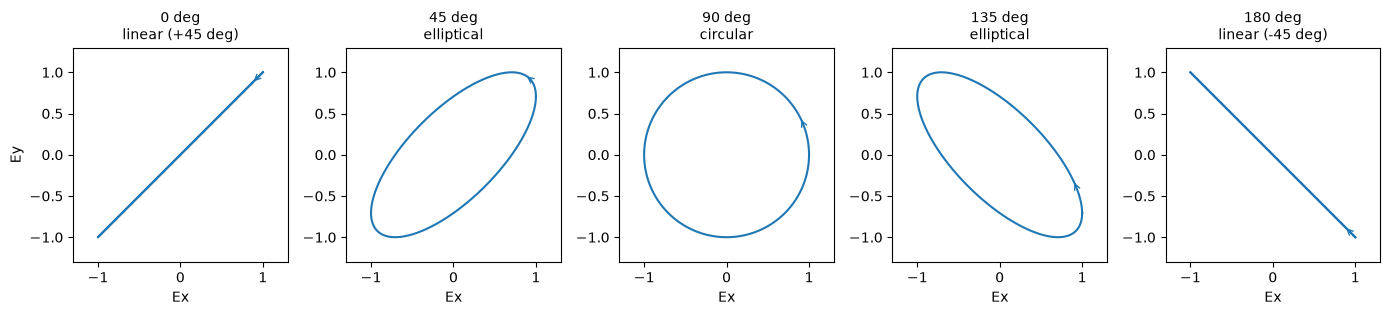

In [27]:
tau = np.linspace(0, 2 * np.pi, 400)
phase_diffs = [0, 45, 90, 135, 180]
labels = ["linear (+45 deg)", "elliptical", "circular", "elliptical", "linear (-45 deg)"]

fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax, dphi, lab in zip(axes, phase_diffs, labels):
    ex = np.cos(tau)
    ey = np.cos(tau - np.deg2rad(dphi))      # Ey lags Ex by dphi
    ax.plot(ex, ey)
    ax.annotate("", xy=(ex[30], ey[30]), xytext=(ex[25], ey[25]),
                arrowprops=dict(arrowstyle="->", color="tab:blue"))   # direction of rotation
    ax.set_title(f"{dphi} deg\n{lab}", fontsize=10)
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_aspect("equal")
    ax.set_xlabel("Ex")
axes[0].set_ylabel("Ey")
plt.tight_layout()
plt.show()

Now the simulated data. The color of the curve shows time. Both curves start and end at the origin because the field is zero before and after the pulse, and the radius grows and shrinks with the pulse envelope.

The incident pulse has equal $E_x$ and $E_y$ in phase, so its curve is a straight line at 45°. Behind the slab the field vector rotates instead of oscillating along a line. Near the peak of the pulse the loops are close to circles, which is the circular polarization we wanted. The loops at the beginning and at the end of the pulse are noticeably elliptical. A pulse is not a monochromatic wave, and the curve is not a perfect circle for three reasons:

* The two components travel at different speeds in the slab, so the envelope of $E_y$ is delayed relative to the envelope of $E_x$ (the printed number below is the delay). At the beginning of the pulse $E_x$ is stronger than $E_y$ and the loops are stretched along $x$ (dark blue). At the end it is the other way round and they are stretched along $y$ (teal).
* The retardation depends on frequency. It is about 85° at the center frequency but differs across the bandwidth of the pulse (section 8). Each frequency component traces its own ellipse and the curve is the sum of all of them.
* $E_x$ and $E_y$ are transmitted with slightly different amplitudes, because the two indices give different reflections at the slab faces.

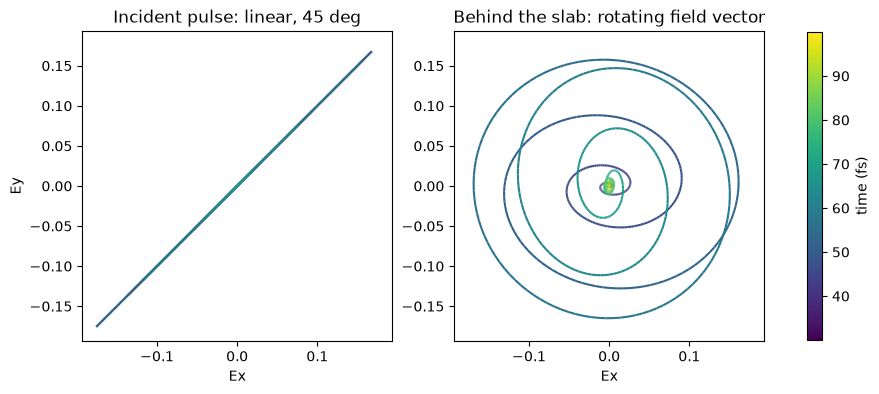

Ey envelope is delayed by 1.40 fs relative to Ex
Sense of rotation behind the slab: counterclockwise (Ey lags Ex, as expected for n_o > n_e)


In [30]:
def colored_curve(ax, x, y, t, cmap="viridis"):
    points = np.column_stack([x, y]).reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    lc = LineCollection(segments, cmap=cmap, norm=plt.Normalize(t.min(), t.max()))
    lc.set_array(t[:-1])
    ax.add_collection(lc)
    return lc

window = (t_fs > 30) & (t_fs < 100)   # the part of the trace that contains the pulse
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
lim = 1.1 * max(np.abs(ex_in).max(), np.abs(ey_in).max())

lc = colored_curve(axes[0], ex_in[window], ey_in[window], t_fs[window])
axes[0].set_title("Incident pulse: linear, 45 deg")
colored_curve(axes[1], ex_out[window], ey_out[window], t_fs[window])
axes[1].set_title("Behind the slab: rotating field vector")
for ax in axes:
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("Ex")
axes[0].set_ylabel("Ey")
fig.colorbar(lc, ax=axes, label="time (fs)", shrink=0.8)
plt.show()

# delay between the envelopes: centroid of the energy of each component in time
def centroid(x):
    return np.sum(t_fs * x**2) / np.sum(x**2)
print(f"Ey envelope is delayed by {centroid(ey_out) - centroid(ex_out):.2f} fs relative to Ex")

# sense of rotation: sign of the area swept by the field vector (positive = counterclockwise)
swept = np.sum(ex_out[:-1] * ey_out[1:] - ey_out[:-1] * ex_out[1:])
print("Sense of rotation behind the slab:", "counterclockwise" if swept > 0 else "clockwise",
      "(Ey lags Ex, as expected for n_o > n_e)")

## 8. Spectrum and retardation versus frequency

The traces above contain all frequencies of the pulse. A Fourier transform separates them. For each polarization component we compute the transfer function of the slab,

$$H_{x,y}(f) = \frac{\mathcal{F}[E_{x,y}^{\mathrm{slab}}](f)}{\mathcal{F}[E_{x,y}^{\mathrm{incident}}](f)},$$

using the run with the slab and the run without it. The amplitude $|H|$ is the transmission and $\arg(H_x/H_y)$ is the phase retardation between the two components. The incident components have equal phase, so the retardation at the detector is the retardation caused by the slab.

We compare the result with two analytic expressions:

* the simple formula $\Delta\varphi = 2\pi (n_o - n_e)\, d\, f / c$ from section 3, which assumes a single pass through the slab, and
* the exact transmission of a lossless slab in vacuum at normal incidence, which includes the multiple reflections between the two faces:
$$ t(f) = \frac{(1 - r^2)\, e^{i k n d}}{1 - r^2 e^{2 i k n d}}, \qquad r = \frac{1 - n}{1 + n}, \qquad k = \frac{2\pi f}{c}.$$

We evaluate $t$ separately with $n = n_e$ for $E_x$ and $n = n_o$ for $E_y$. Since the Fourier transform of the recorded signals gives phases of the form $e^{-i k n d}$, the code below uses the complex conjugate of this expression.

Retardation at 193.4 THz (1550 nm):
  simulation:                   84.8 deg
  exact slab (with reflections):  84.7 deg
  simple formula (single pass):   90.0 deg
Transmitted amplitude at 193.4 THz: |Hx| = 0.946, |Hy| = 0.961


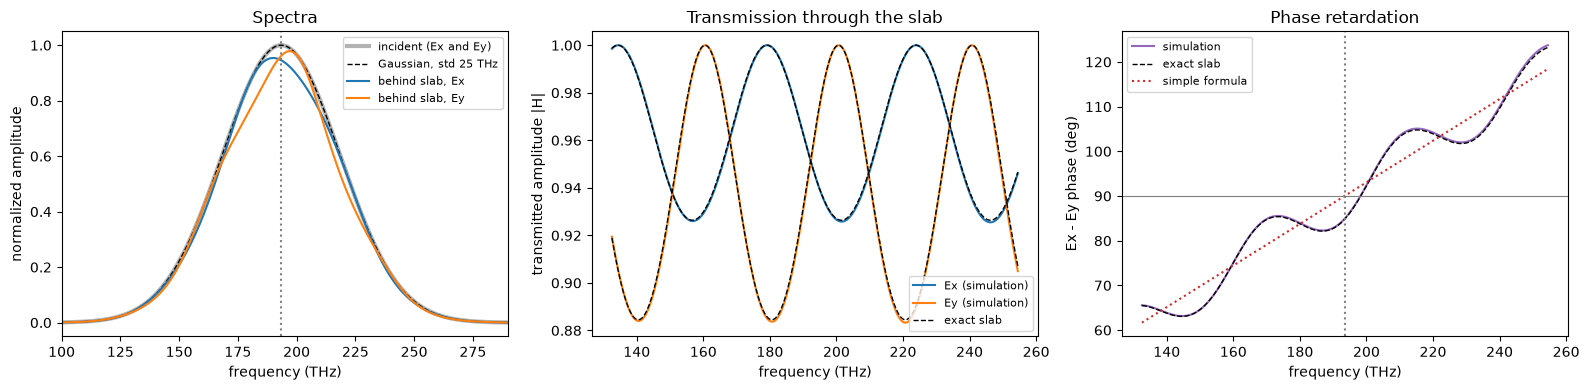

In [33]:
n_fft = 2**16                                    # zero-padding gives a smoother spectrum
dt = config.time_step_duration
freqs = np.fft.rfftfreq(n_fft, d=dt)
F_in = np.fft.rfft(np.stack([ex_in, ey_in], axis=1), n_fft, axis=0)
F_out = np.fft.rfft(np.stack([ex_out, ey_out], axis=1), n_fft, axis=0)
H = F_out / F_in                                 # transfer function of the slab, columns: Ex, Ey

# Only use frequencies where the incident pulse has enough power (> 5% of its peak amplitude)
band = np.abs(F_in[:, 0]) > 0.05 * np.abs(F_in[:, 0]).max()

def slab_transmission(n, f, d):
    """Exact transmission of a lossless slab (index n, thickness d) in vacuum, normal incidence.
    Referenced to propagation through the same distance in vacuum. Uses the exp(-i k n d)
    phase convention of numpy's FFT."""
    k = 2 * np.pi * f / c0
    r = (1 - n) / (1 + n)
    num = (1 - r**2) * np.exp(-1j * k * n * d)
    den = 1 - r**2 * np.exp(-2j * k * n * d)
    return num / den * np.exp(1j * k * d)

t_x = slab_transmission(n_e, freqs, slab_thickness)
t_y = slab_transmission(n_o, freqs, slab_thickness)

retard_sim = np.degrees(np.angle(H[:, 0] / H[:, 1]))
retard_exact = np.degrees(np.angle(t_x / t_y))
retard_simple = np.degrees(2 * np.pi * delta_n * slab_thickness * freqs / c0)

f_thz = freqs / 1e12
i0 = np.argmin(np.abs(freqs - f0))
print(f"Retardation at {f0/1e12:.1f} THz ({wavelength*1e9:.0f} nm):")
print(f"  simulation:                  {retard_sim[i0]:5.1f} deg")
print(f"  exact slab (with reflections): {retard_exact[i0]:5.1f} deg")
print(f"  simple formula (single pass):  {retard_simple[i0]:5.1f} deg")
print(f"Transmitted amplitude at {f0/1e12:.1f} THz: |Hx| = {abs(H[i0, 0]):.3f}, |Hy| = {abs(H[i0, 1]):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (1) spectra
spec_in = np.abs(F_in[:, 0]) / np.abs(F_in[:, 0]).max()
gauss = np.exp(-(freqs - f0) ** 2 / (2 * (25e12) ** 2))     # Gaussian with the std we set in the source
axes[0].plot(f_thz, spec_in, color="gray", lw=3, alpha=0.6, label="incident (Ex and Ey)")
axes[0].plot(f_thz, gauss, "k--", lw=1, label="Gaussian, std 25 THz")
axes[0].plot(f_thz, np.abs(F_out[:, 0]) / np.abs(F_in[:, 0]).max(), color="tab:blue", label="behind slab, Ex")
axes[0].plot(f_thz, np.abs(F_out[:, 1]) / np.abs(F_in[:, 0]).max(), color="tab:orange", label="behind slab, Ey")
axes[0].axvline(f0 / 1e12, color="gray", ls=":")
axes[0].set_xlim(100, 290)
axes[0].set_xlabel("frequency (THz)")
axes[0].set_ylabel("normalized amplitude")
axes[0].set_title("Spectra")
axes[0].legend(fontsize=8)

# (2) transmission
axes[1].plot(f_thz[band], np.abs(H[band, 0]), color="tab:blue", label="Ex (simulation)")
axes[1].plot(f_thz[band], np.abs(H[band, 1]), color="tab:orange", label="Ey (simulation)")
axes[1].plot(f_thz[band], np.abs(t_x[band]), "k--", lw=1, label="exact slab")
axes[1].plot(f_thz[band], np.abs(t_y[band]), "k--", lw=1)
axes[1].set_xlabel("frequency (THz)")
axes[1].set_ylabel("transmitted amplitude |H|")
axes[1].set_title("Transmission through the slab")
axes[1].legend(fontsize=8)

# (3) retardation
axes[2].plot(f_thz[band], retard_sim[band], color="tab:purple", label="simulation")
axes[2].plot(f_thz[band], retard_exact[band], "k--", lw=1, label="exact slab")
axes[2].plot(f_thz[band], retard_simple[band], ":", color="tab:red", label="simple formula")
axes[2].axhline(90, color="gray", lw=0.8)
axes[2].axvline(f0 / 1e12, color="gray", ls=":")
axes[2].set_xlabel("frequency (THz)")
axes[2].set_ylabel("Ex - Ey phase (deg)")
axes[2].set_title("Phase retardation")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

**Spectra.** A Gaussian pulse in time has a Gaussian spectrum. The incident spectrum (gray) lies on top of the Gaussian curve (black dashed) that has the center frequency and the standard deviation we gave to the source. Behind the slab the spectrum is this Gaussian multiplied by the transmission of the slab. The transmission is not constant (next panel), so the spectra of $E_x$ and $E_y$ are slightly distorted and differ from each other, but the overall shape stays close to the Gaussian.

**Transmission.** The transmitted amplitude is between about 0.88 and 1 and oscillates with frequency. Each slab face reflects roughly 4 to 6 percent of the power, and the waves reflected inside the slab interfere with the transmitted wave. This is a Fabry-Perot effect. The amplitude reaches 1 where the reflections cancel. Since $n_e$ and $n_o$ differ, the oscillations for $E_x$ and $E_y$ are shifted against each other.

**Retardation.** The simulation follows the exact slab calculation closely over the whole band. The simple formula gives a retardation that is exactly linear in frequency and equals 90° at 193 THz (1550 nm). The exact result and the simulation oscillate around this line. At 1550 nm they give about 85°, so the slab is not a perfect quarter-wave plate in practice. The deviation comes from the multiple reflections inside the slab, not from numerical error. To get exactly 90° one would adjust the thickness slightly or add antireflection coatings.